Iteration 1: value updated, delta = 1.000000
Iteration 2: value updated, delta = 0.900000
Iteration 3: value updated, delta = 0.810000
Iteration 4: value updated, delta = 0.729000
Iteration 5: value updated, delta = 0.656100
Iteration 6: value updated, delta = 0.590490
Value converged after 7 iterations.


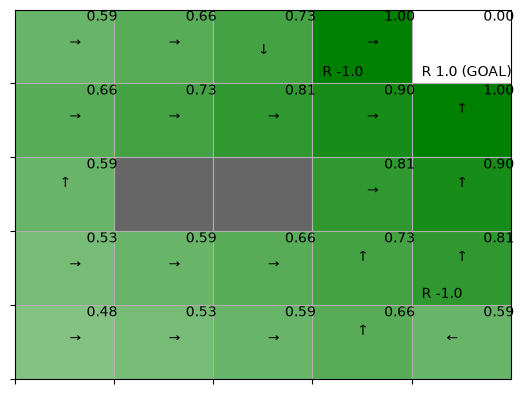

In [3]:
if '__file__' in globals():
    import os, sys
    sys.path.append(os.path.join(os.path.dirname(__file__), '..'))
from collections import defaultdict
from common.gridworld import GridWorld
from policy_iter import greedy_policy


def value_iter_onestep(V, env, gamma):
    for state in env.states():       # 모든 상태에 차례로 접근
        if state == env.goal_state:  # 목표 상태에서의 가치 함수는 항상 0
            V[state] = 0
            continue

        action_values = []
        for action in env.actions():  # 모든 행동에 차례로 접근
            next_state = env.next_state(state, action)
            r = env.reward(state, action, next_state)
            value = r + gamma * V[next_state]  # 새로운 가치 함수
            action_values.append(value)

        V[state] = max(action_values)  # 최댓값 추출
    return V


def value_iter(V, env, gamma, threshold=0.001):
    iteration = 0
    while True:
        iteration += 1
        old_V = V.copy()  # 갱신 전 가치 함수
        V = value_iter_onestep(V, env, gamma)

        # 갱신된 양의 최댓값 구하기
        delta = 0
        for state in V.keys():
            t = abs(V[state] - old_V[state])
            if delta < t:
                delta = t

        if delta < threshold:
            print(f"Value converged after {iteration} iterations.")
            break

        print(f"Iteration {iteration}: value updated, delta = {delta:.6f}")

        # 임계값과 비교
        if delta < threshold:
            break
    return V


if __name__ == '__main__':
    V = defaultdict(lambda: 0)
    env = GridWorld()
    gamma = 0.9

    V = value_iter(V, env, gamma)  # 최적 가치 함수 찾기
    pi = greedy_policy(V, env, gamma)  # 최적 정책 찾기
    env.render_v(V, pi)